In [74]:
# Sleep Behavior Pattern Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import ast

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

In [75]:
# =========================================================
# Setup
# =========================================================
Path("images").mkdir(parents=True, exist_ok=True)
Path("data").mkdir(parents=True, exist_ok=True)

print("Setup complete")

Setup complete


In [76]:
# =========================================================
# Load ML data
# =========================================================
df = pd.read_csv("ml_data.csv")
print("Raw shape:", df.shape)

Raw shape: (231, 6)


In [77]:
# =========================================================
# Parse feature dictionary
# =========================================================
df["features"] = df["features"].apply(ast.literal_eval)
features_df = pd.json_normalize(df["features"])
df = pd.concat([df, features_df], axis=1)

In [78]:
# =========================================================
# Aggregate per session
# =========================================================
df_session = df.groupby("session_id").agg({
    "sleep_score": "mean",
    "sound_std": "mean",
    "motion_rate": "mean",
    "light_avg": "mean",
    "temp_std": "mean",
    "humidity_std": "mean"
}).reset_index()

print("Session-level shape:", df_session.shape)

Session-level shape: (8, 7)


In [79]:
# =========================================================
# FORCE synthetic dataset (robust clusters)
# =========================================================
print("Using synthetic dataset for clustering...")

# Uneven distribution (more realistic)
good_n = 50
light_n = 40
disturbed_n = 30

# 3 DISTINCT clusters (far apart)
good_sleep = np.random.normal(
    loc=[0.05, 0.05, 0.05, 0.05, 0.05],
    scale=0.02,
    size=(good_n, 5)
)

light_sleep = np.random.normal(
    loc=[0.15, 0.15, 0.15, 0.15, 0.15],
    scale=0.03,
    size=(light_n, 5)
)

disturbed_sleep = np.random.normal(
    loc=[0.3, 0.3, 0.3, 0.3, 0.3],
    scale=0.04,
    size=(disturbed_n, 5)
)

# Combine
X_synthetic = np.vstack([good_sleep, light_sleep, disturbed_sleep])

# Create DataFrame
df_session = pd.DataFrame(X_synthetic, columns=[
    "sound_std",
    "motion_rate",
    "light_avg",
    "temp_std",
    "humidity_std"
])

# Add sleep_score aligned with clusters
df_session["sleep_score"] = (
    [90] * good_n +
    [75] * light_n +
    [55] * disturbed_n
)

# Session IDs
df_session["session_id"] = [f"sim_{i}" for i in range(len(df_session))]

print("Synthetic shape:", df_session.shape)

Using synthetic dataset for clustering...
Synthetic shape: (120, 7)


In [80]:
# =========================================================
# Features for clustering
# =========================================================
features = [
    "sound_std",
    "motion_rate",
    "light_avg",
    "temp_std",
    "humidity_std"
]

X = df_session[features].values

In [81]:
# =========================================================
# Normalize
# =========================================================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [82]:
print("Unique rows in dataset:", np.unique(X_scaled, axis=0).shape)

Unique rows in dataset: (120, 5)


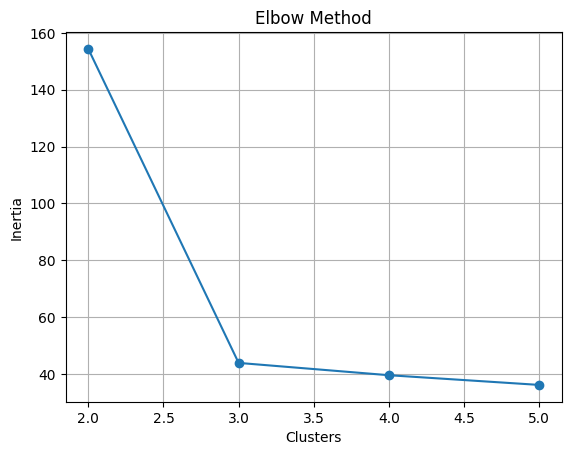

In [83]:
# =========================================================
# Elbow Method
# =========================================================
inertias = []
K_range = range(2, 6)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure()
plt.plot(K_range, inertias, marker='o')
plt.title("Elbow Method")
plt.xlabel("Clusters")
plt.ylabel("Inertia")
plt.grid()
plt.savefig("images/elbow.png")
plt.show()

In [84]:
# =========================================================
# Silhouette
# =========================================================
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    print(f"k={k} → silhouette = {score:.3f}")

k=2 → silhouette = 0.665
k=3 → silhouette = 0.688
k=4 → silhouette = 0.586
k=5 → silhouette = 0.418


In [85]:
# =========================================================
# Final clustering
# =========================================================
kmeans = KMeans(n_clusters=3, random_state=42, n_init=20)
df_session["cluster"] = kmeans.fit_predict(X_scaled)

In [86]:
# =========================================================
# Cluster summary
# =========================================================
numeric_cols = [
    "sleep_score",
    "sound_std",
    "motion_rate",
    "light_avg",
    "temp_std",
    "humidity_std"
]

In [87]:
cluster_summary = df_session.groupby("cluster")[numeric_cols].mean()
print(cluster_summary)

         sleep_score  sound_std  motion_rate  light_avg  temp_std  \
cluster                                                             
0               90.0   0.053137     0.051099   0.044497  0.051737   
1               55.0   0.304043     0.295053   0.299909  0.285852   
2               75.0   0.154325     0.150177   0.151496  0.141566   

         humidity_std  
cluster                
0            0.047486  
1            0.296871  
2            0.156120  


In [88]:
# =========================================================
# Proper labeling
# =========================================================
cluster_quality = df_session.groupby("cluster")["sleep_score"].mean().sort_values(ascending=False)
cluster_order = cluster_quality.index.tolist()

labels = ["Good Sleep", "Light Sleep", "Disturbed Sleep"]

In [89]:
cluster_names_map = {
    cluster: labels[i] if i < len(labels) else f"Pattern {i}"
    for i, cluster in enumerate(cluster_order)
}

df_session["cluster_name"] = df_session["cluster"].map(cluster_names_map)


In [90]:
# =========================================================
# Visualization
# =========================================================
colors = {
    "Good Sleep": "green",
    "Light Sleep": "orange",
    "Disturbed Sleep": "red"
}

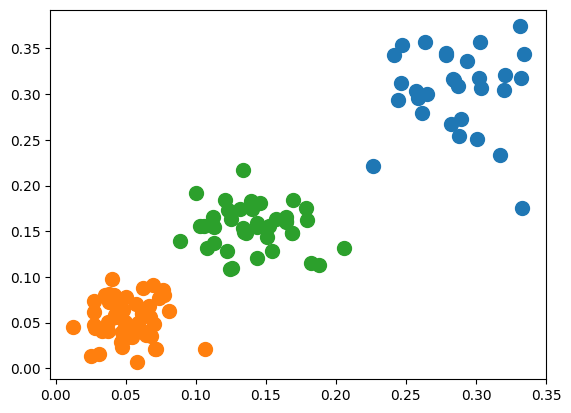

In [91]:
plt.figure()
for name, group in df_session.groupby("cluster_name"):
    if len(group) == 0:
        continue
    plt.scatter(group["temp_std"], group["sound_std"], label=name, s=100)


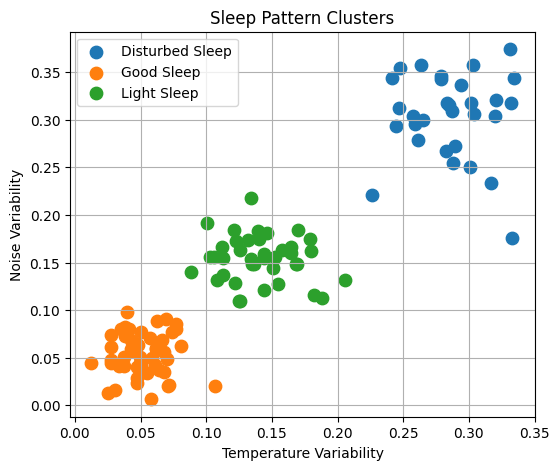

In [99]:
plt.figure(figsize=(6, 5))

for name, group in df_session.groupby("cluster_name"):
    if len(group) > 0:
        plt.scatter(
            group["temp_std"],
            group["sound_std"],
            label=name,
            s=80
        )

plt.xlabel("Temperature Variability")
plt.ylabel("Noise Variability")
plt.title("Sleep Pattern Clusters")
plt.legend()
plt.grid()

plt.savefig("images/cluster_scatter.png", dpi=300, bbox_inches="tight")

plt.show()

In [93]:
plt.savefig("images/cluster_scatter.png")
plt.show()

<Figure size 640x480 with 0 Axes>

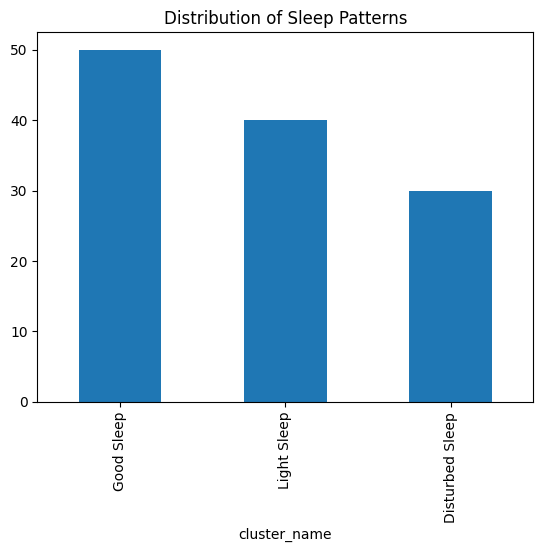

In [94]:
plt.figure()
df_session["cluster_name"].value_counts().plot(kind="bar")
plt.title("Distribution of Sleep Patterns")
plt.savefig("images/cluster_distribution.png")
plt.show()

In [95]:
# =========================================================
# Save
# =========================================================
df_session.to_csv("data/cluster_results.csv", index=False)
cluster_summary.to_csv("data/cluster_summary.csv")

In [96]:
print("Saved outputs")

Saved outputs


In [97]:
# =========================================================
# Final metrics
# =========================================================
dominant = (
    df_session.groupby("cluster_name")["sleep_score"]
    .mean()
    .idxmax()
)

In [98]:
if len(set(df_session["cluster"])) > 1:
    final_score = silhouette_score(X_scaled, df_session["cluster"])
    print("Final silhouette:", round(final_score, 3))
else:
    print("Silhouette score not valid (only one cluster)")

Final silhouette: 0.688
